# 04 · Clima × produtividade

**Coffee Big Data Intelligence**

> **Aviso central:** este notebook mede **associação**, não causalidade. Com ~13 safras e clima de grade (~55 km), qualquer relação é *exploratória*. Clima, bienalidade, manejo e preço variam juntos.

## Objetivos
1. Construir **features climáticas por janela fenológica** sem vazamento de informação.
2. Medir associações entre **anomalias** climáticas e de rendimento, com incerteza que respeite a **pequena quantidade de anos**.
3. Entender por que milhares de municípios **não** equivalem a milhares de observações independentes de clima.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coffeebdi import config, silver, modeling as M, quality
from coffeebdi.lake import Lake
from coffeebdi.nbutils import duck, mpl_style

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.2f}".format)
mpl_style()
lake = Lake()
con = duck(lake)
def q(sql):
    """Executa SQL (DuckDB) sobre as tabelas silver/gold e devolve DataFrame."""
    return con.execute(sql).df()
FIG = config.OUTPUTS / "figures"
from scipy import stats

## 1. Janelas fenológicas (ano-colheita *t*)

| Feature | Janela | Intuição agronômica (hipótese) |
|---|---|---|
| `chuva_floracao`, `tmean_floracao` | set–nov de *t*−1 | chuva/temperatura na florada determinam pegamento |
| `chuva_granacao`, `tmax_granacao` | dez *t*−1 – mar *t* | enchimento de grãos; calor + déficit hídrico prejudicam |
| `chuva_12m_pre` | abr *t*−1 – mar *t* | disponibilidade hídrica do ciclo |
| `dias_frio_inv_prev` | dias com T2M_MIN ≤ 4 °C em jun–ago *t*−1 | frio/geada afetando ramos e gemas |

**Todas terminam em 31/mar de *t*** — antes da data de corte de previsão (1º/mai de *t*). Épocas reais variam com região, altitude e cultivar; estas janelas são **simplificações**. O limiar de 4 °C na *grade* de ~55 km **subestima** geadas locais (o relevo cria cold-pockets que a reanálise não vê).

In [2]:
f = q("select * from clima_features where ano = 2022 limit 3")
print("Teste de não-vazamento embutido nas features: última data usada < data de corte em todas as linhas?",
      bool(q("select bool_and(ultima_data_usada < data_corte_previsao) from clima_features").iloc[0, 0]))
f[["cell_id", "ano", "chuva_floracao", "chuva_granacao", "tmax_granacao", "chuva_12m_pre", "dias_frio_inv_prev", "ultima_data_usada", "data_corte_previsao"]]

Teste de não-vazamento embutido nas features: última data usada < data de corte em todas as linhas? True


,cell_id,ano,chuva_floracao,chuva_granacao,tmax_granacao,chuva_12m_pre,dias_frio_inv_prev,ultima_data_usada,data_corte_previsao
0,-40_-76,2022,382.14,807.36,27.81,"1,291.68",0.00,2022-03-31,2022-05-01
1,-40_-77,2022,389.48,736.97,29.52,"1,213.97",0.00,2022-03-31,2022-05-01
2,-40_-79,2022,343.26,649.08,30.72,"1,065.17",0.00,2022-03-31,2022-05-01


## 2. Sazonalidade climática nas células produtoras

Climatologia 2000–2025 das células com mais produção de arábica.

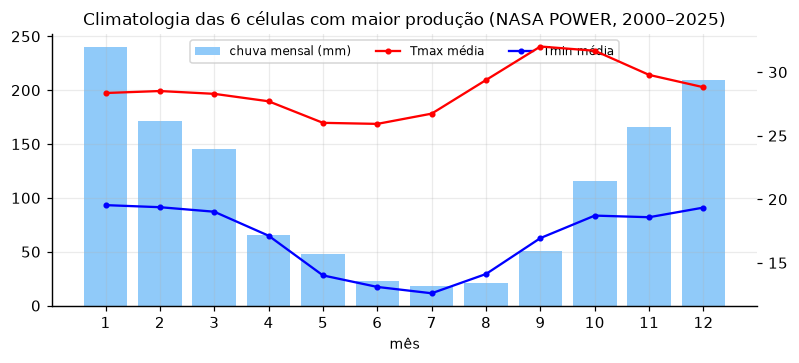

Chuva jun–ago: 62 mm/trimestre vs dez–fev: 621 mm/trimestre


In [3]:
top_cells = q('''
SELECT d.cell_id, sum(m.quantidade_t) AS prod FROM pam_municipio m JOIN dim_municipio d USING (cod_ibge)
WHERE m.especie='arabica' AND m.ano >= 2012 GROUP BY 1 ORDER BY 2 DESC LIMIT 6''').cell_id.tolist()
cl = q(f"select cell_id, mes, avg(prec_mm) as prec, avg(tmax_mean) as tmax, avg(tmin_mean) as tmin from clima_mensal where cell_id in ({','.join(repr(c) for c in top_cells)}) group by 1, 2")
mes = cl.groupby("mes").agg(prec=("prec", "mean"), tmax=("tmax", "mean"), tmin=("tmin", "mean"))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(mes.index, mes.prec, color="#90caf9", label="chuva mensal (mm)"); ax.set_xticks(range(1, 13)); ax.set_xlabel("mês")
ax2 = ax.twinx(); ax2.plot(mes.index, mes.tmax, "r-o", ms=3, label="Tmax média"); ax2.plot(mes.index, mes.tmin, "b-o", ms=3, label="Tmin média"); ax2.grid(False)
ax.set_title("Climatologia das 6 células com maior produção (NASA POWER, 2000–2025)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper center", fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig(FIG / "04_climatologia.png"); plt.show()
print(f"Chuva jun–ago: {mes.loc[6:8,'prec'].sum():.0f} mm/trimestre vs dez–fev: {mes.loc[[12,1,2],'prec'].sum():.0f} mm/trimestre")

**Como ler:** barras = chuva média mensal; linhas = temperaturas máxima (vermelha) e mínima (azul). O padrão **verão quente e chuvoso / inverno mais frio e seco** é o ciclo em que as janelas fenológicas foram desenhadas.

## 3. Quadro de análise: anomalias

Para separar efeito de ano de efeito de município, trabalhamos com **anomalias**: rendimento menos a média do município; feature menos a média da célula.

In [4]:
FEATS = M.CLIMA
d = q("select * from painel_cafe_arabica where elegivel_modelo").dropna(subset=FEATS + ["rendimento_kg_ha", "rend_lag1"]).copy()
d["y_anom"] = d.rendimento_kg_ha - d.groupby("cod_ibge").rendimento_kg_ha.transform("mean")
d["lag1_anom"] = d.rend_lag1 - d.groupby("cod_ibge").rend_lag1.transform("mean")
for c in FEATS:
    d[c + "_anom"] = d[c] - d.groupby("cell_id")[c].transform("mean")
print(f"Linhas município-ano: {len(d):,} | municípios: {d.cod_ibge.nunique()} | ANOS distintos: {d.ano.nunique()} ({d.ano.min()}–{d.ano.max()}) | células: {d.cell_id.nunique()}")
print(f"=> Informação independente sobre efeitos de ANO: ~{d.ano.nunique()} observações, não {len(d):,}.")

Linhas município-ano: 1,663 | municípios: 167 | ANOS distintos: 13 (2013–2025) | células: 45
=> Informação independente sobre efeitos de ANO: ~13 observações, não 1,663.


Esta última linha é a mais importante: as features climáticas variam **principalmente entre anos** (e entre poucas células), e todos os municípios de uma célula compartilham o mesmo clima. Milhares de linhas **não** são milhares de experimentos independentes.

## 4. Correlações (Spearman) com incerteza por *bootstrap de anos* e *leave-one-year-out*

- **IC por bootstrap em blocos de ano:** reamostra anos inteiros (preserva a dependência dentro do ano).
- **Leave-one-year-out (LOYO):** estabilidade do sinal ao remover cada ano.
- Controle da **bienalidade:** correlação parcial removendo a anomalia do rendimento do ano anterior.

In [5]:
def spearman(x, y):
    return stats.spearmanr(x, y)[0]

def partial_spearman(df, x, y, z):
    r = df[[x, y, z]].rank()
    rx = r[x] - np.polyval(np.polyfit(r[z], r[x], 1), r[z])
    ry = r[y] - np.polyval(np.polyfit(r[z], r[y], 1), r[z])
    return np.corrcoef(rx, ry)[0, 1]

rng = np.random.default_rng(0)
anos = d.ano.unique()
groups = {a: g for a, g in d.groupby("ano")}
rows = []
for c in FEATS:
    x = c + "_anom"
    rho = spearman(d[x], d.y_anom)
    boots = []
    for _ in range(500):
        samp = pd.concat([groups[a] for a in rng.choice(anos, len(anos), replace=True)])
        boots.append(spearman(samp[x], samp.y_anom))
    loyo = [spearman(d[d.ano != a][x], d[d.ano != a].y_anom) for a in anos]
    rows.append({"feature": c, "rho": rho, "IC95_inf": np.percentile(boots, 2.5), "IC95_sup": np.percentile(boots, 97.5),
                 "LOYO_min": min(loyo), "LOYO_max": max(loyo), "rho_parcial(|lag1)": partial_spearman(d, x, "y_anom", "lag1_anom")})
corr = pd.DataFrame(rows).set_index("feature")
corr["IC inclui 0?"] = (corr.IC95_inf < 0) & (corr.IC95_sup > 0)
corr.round(3)

,rho,IC95_inf,IC95_sup,LOYO_min,LOYO_max,rho_parcial(|lag1),IC inclui 0?
feature,,,,,,,
chuva_floracao,0.06,-0.04,0.17,0.02,0.08,0.06,True
tmean_floracao,0.09,-0.06,0.20,0.05,0.12,0.07,True
chuva_granacao,-0.01,-0.14,0.12,-0.06,0.03,0.03,True
tmax_granacao,0.03,-0.10,0.14,-0.01,0.08,0.00,True
chuva_12m_pre,-0.03,-0.12,0.08,-0.06,0.01,0.01,True
dias_frio_inv_prev,0.04,-0.03,0.13,0.02,0.06,0.04,True


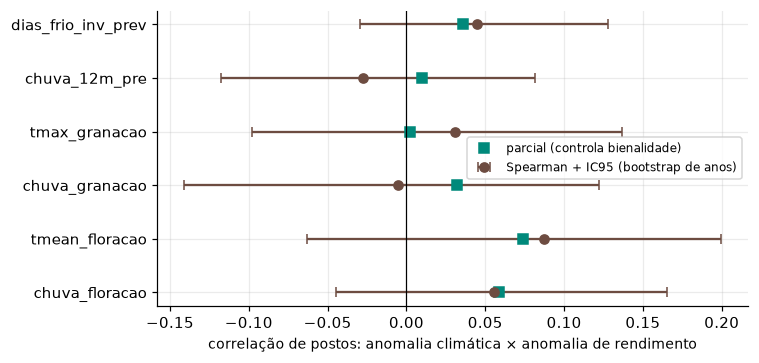

Correlação (Spearman) da anomalia municipal com a do ano anterior: 0.228


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(corr))
ax.errorbar(corr.rho, y, xerr=[corr.rho - corr.IC95_inf, corr.IC95_sup - corr.rho], fmt="o", color="#6d4c41", capsize=3, label="Spearman + IC95 (bootstrap de anos)")
ax.plot(corr["rho_parcial(|lag1)"], y, "s", color="#00897b", label="parcial (controla bienalidade)")
ax.axvline(0, color="k", lw=.8); ax.set_yticks(y); ax.set_yticklabels(corr.index); ax.set_xlabel("correlação de postos: anomalia climática × anomalia de rendimento"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_correlacoes.png"); plt.show()
print("Correlação (Spearman) da anomalia municipal com a do ano anterior:", round(spearman(d.lag1_anom, d.y_anom), 3))

**Como ler:** pontos marrons com barras = correlação e IC95 por bootstrap de **anos**; quadrados verdes = correlação parcial após controlar a anomalia do ano anterior. Intervalo que **inclui 0** = sem evidência de associação. O número impresso mede a **persistência municipal** (anomalia × anomalia do ano anterior). Interprete o sinal pelo valor impresso, não por expectativa: anomalias em relação à média do município herdam a **tendência** do período e as **estimativas repetidas** (notebook 02), ambas gerando persistência positiva que mascara a alternância bienal. A bienalidade aparece no **nível estadual** (seção 5).

**O que NÃO concluir:** (i) que "chuva na florada *causa* produtividade"; (ii) que a ausência de correlação prove que clima não importa — a resolução (55 km), as estimativas administrativas repetidas (notebook 02) e a pequena quantidade de anos **atenuam e escondem** efeitos reais; (iii) que o sinal seja estável: confira o intervalo LOYO.

## 5. Nível de ano: clima médio × rendimento paulista

Para fugir da ilusão de n grande, comparamos **um ponto por ano**.

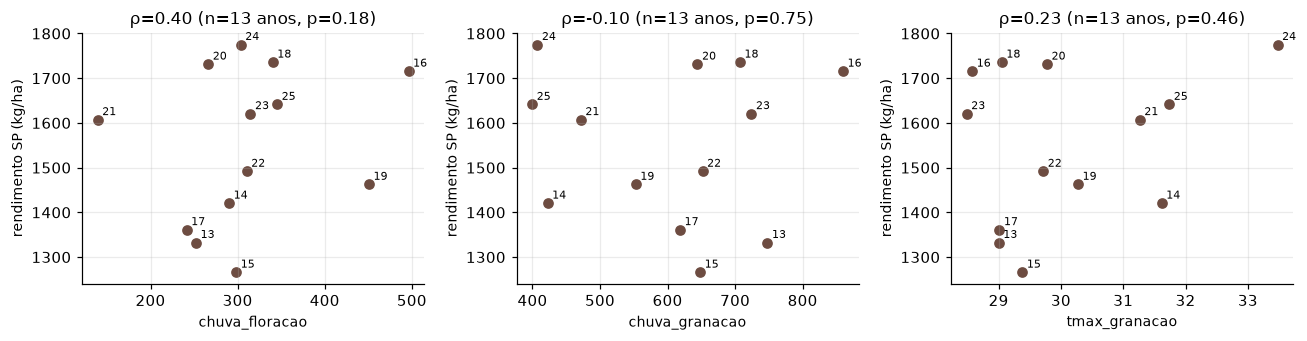

In [7]:
yr = d.groupby("ano").apply(lambda g: pd.Series({
    "rend_sp": 1000 * g.quantidade_t.sum() / g.area_colhida_ha.sum(),
    **{c: g[c].mean() for c in FEATS}})).reset_index()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for a, c in zip(axs, ["chuva_floracao", "chuva_granacao", "tmax_granacao"]):
    a.scatter(yr[c], yr.rend_sp, color="#6d4c41")
    for _, r in yr.iterrows():
        a.annotate(int(r.ano) % 100, (r[c], r.rend_sp), fontsize=7, xytext=(3, 3), textcoords="offset points")
    rho, p = stats.spearmanr(yr[c], yr.rend_sp)
    a.set(xlabel=c, ylabel="rendimento SP (kg/ha)", title=f"ρ={rho:.2f} (n={len(yr)} anos, p={p:.2f})")
plt.tight_layout(); plt.savefig(FIG / "04_nivel_ano.png"); plt.show()

**Como ler:** cada ponto é uma safra (rótulo = ano com 2 dígitos). Com **n pequeno**, p-valores e ρ são instáveis; a célula abaixo quantifica a alternância (bienalidade) no rendimento estadual.

In [8]:
yr = yr.sort_values("ano").reset_index(drop=True)
det = yr.rend_sp - np.polyval(np.polyfit(yr.ano, yr.rend_sp, 1), yr.ano)
print(f"Rendimento estadual (municípios elegíveis), resíduo sem tendência linear: autocorrelação lag 1 = {det.autocorr(1):.2f}; lag 2 = {det.autocorr(2):.2f} (n={len(yr)} anos)")

Rendimento estadual (municípios elegíveis), resíduo sem tendência linear: autocorrelação lag 1 = -0.66; lag 2 = 0.46 (n=13 anos)


**Bienalidade no nível estadual:** autocorrelação de lag 1 **negativa** = alternância alto/baixo. Essa alternância **confunde** qualquer relação clima–rendimento anual: com ~13 safras não dá para separar "ano de carga alta" de "ano de clima favorável".

## 6. Resumo interpretativo

| Pergunta | O que os dados permitem dizer | O que **não** permitem |
|---|---|---|
| Há associação clima–rendimento? | ver tabela da seção 4 (ICs e LOYO) | causalidade; efeito por talhão |
| Qual o efeito dominante? | **bienalidade** (alternância alto/baixo no nível estadual) | separar bienalidade de efeitos de manejo/poda |
| Clima de grade serve? | para contexto regional e sazonalidade | geada local, déficit hídrico por lavoura, irrigação |

Próximos passos naturais: dados de estações (INMET, validação), balanço hídrico, altitude real por lavoura, produtividade por talhão (como no Projeto 01).

## 7. Exercícios
1. Substitua a anomalia por *z-score* dentro de cada município. A conclusão muda?
2. Teste a janela de geada com limiar de 2 °C e de 6 °C. Que limiar dá mais variação entre anos?
3. Construa o *dummy* de ano par/ímpar e compare sua correlação com `y_anom` à de `chuva_granacao_anom`.